# 01 — EDA of the UCF-Crime dataset (Kaggle version)
*[Owner: TV1]* Run `python scripts/prepare_data.py` first. Tables are written to `results/tables/eda/`, figures to `results/figures/eda/` (used in the report).

In [1]:
import json, os, sys
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
from src.utils.config import load_config
from src.data import eda

cfg = load_config('configs/base.yaml')

## Overview
Regenerates every table and figure. The noise scan takes ~5 minutes and is reused from the last `python scripts/prepare_data.py --steps eda` run.

In [2]:
summary, tables = eda.run_all(cfg, noise=False)
print(json.dumps(summary, indent=1))

{
 "videos": 1900,
 "frames": 1377653,
 "hours": 127.6,
 "normal_frame_pct": 73.5,
 "longest_video": "Normal_Videos308_x264",
 "longest_hours": 9.0,
 "pixel_mean": [
  0.3478,
  0.3438,
  0.3382
 ],
 "pixel_std": [
  0.2741,
  0.2738,
  0.2736
 ]
}


## Class distribution
Normal videos make up ~50% of the videos but ~74% of the frames, because they are much longer. The author-defined test split has a different class distribution from the training split (e.g. only 2 Abuse test videos, but 21–23 Explosion, Shooting and Shoplifting test videos).

,videos_train,videos_val,videos_test,frames_train,frames_val,frames_test
label,,,,,,
NormalVideos,720,80,150,886584,61184,64952
Abuse,43,5,2,17490,1586,297
Arrest,41,4,5,25044,1353,3365
Arson,37,4,9,23745,676,2793
Assault,42,5,3,8570,1790,2657
Burglary,78,9,13,35729,3775,7657
Explosion,26,3,21,18329,424,6510
Fighting,41,4,5,23510,1174,1231
RoadAccidents,114,13,23,21886,1600,2663


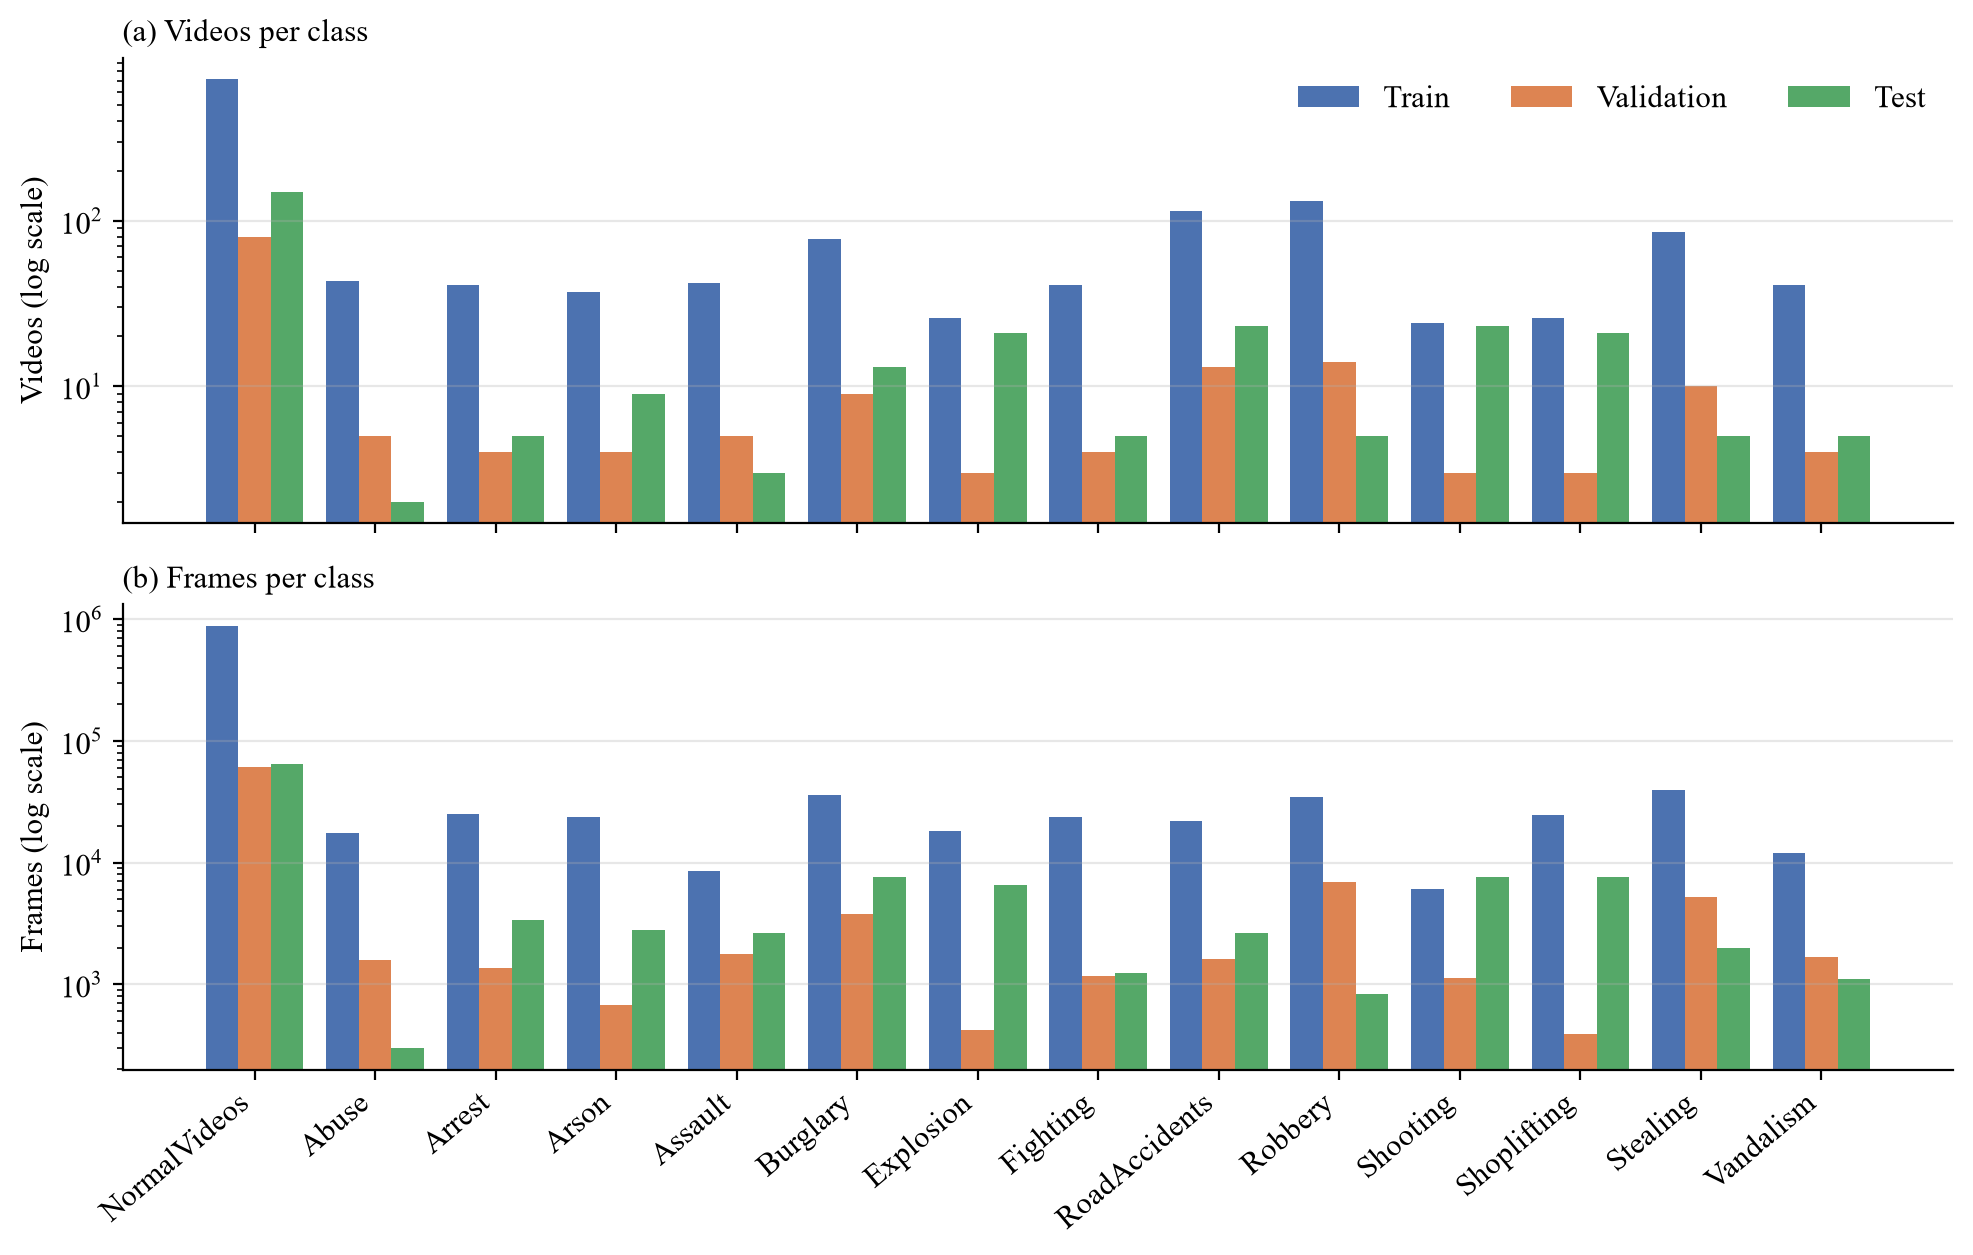

In [3]:
display(tables['class_distribution'])
display(Image(eda.FIG_DIR / 'class_distribution.png'))

## Video duration
Long-tailed: the median video lasts about one minute, but a few Normal videos last hours (up to 9 h). Training therefore keeps at most 64 clips per video.

,min,50%,mean,max
subset,,,,
train,3.7,74.3,270.9,32550.3
val,7.0,73.0,184.1,3599.3
test,5.3,59.8,127.9,3600.0


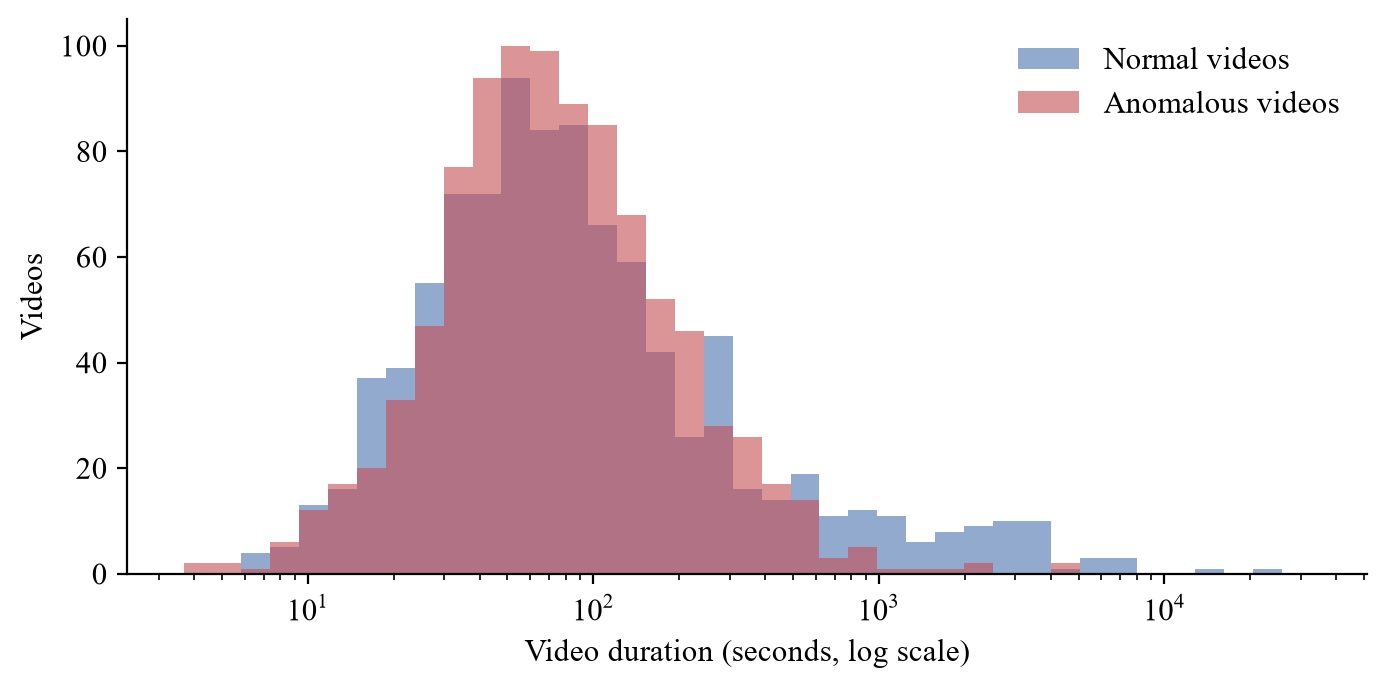

In [4]:
display(tables['duration_seconds'])
display(Image(eda.FIG_DIR / 'duration.png'))

## Anomalous frames in the test set
Only 7.7% of the test frames are anomalous, and only ~18% of the frames of an anomalous video lie inside the annotated segment: video-level training labels are very noisy, which motivates MIL.

,frames,anomalous,pct
NormalVideos,64952,0,0.00
Abuse,297,17,5.72
Arrest,3365,783,23.27
Arson,2793,823,29.47
Assault,2657,854,32.14
Burglary,7657,1623,21.20
Explosion,6510,778,11.95
Fighting,1231,448,36.39
RoadAccidents,2663,243,9.13
Robbery,835,385,46.11


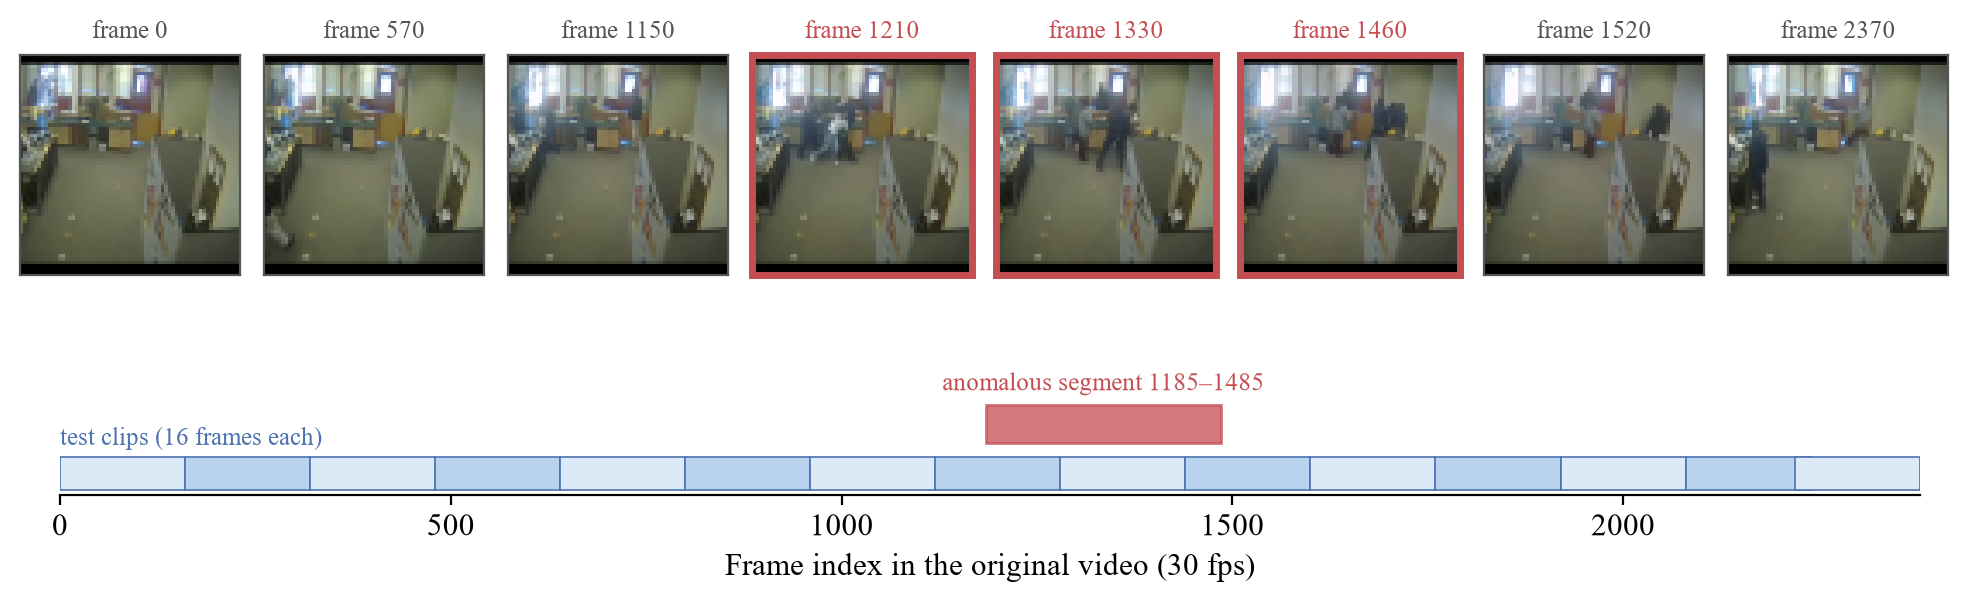

In [5]:
display(tables['test_anomaly'])
display(Image(eda.FIG_DIR / 'label_example.png'))

## Clips

In [6]:
display(tables['clips'])

,videos,normal_videos,anomaly_videos,frames,clips,anomaly_clips,anomaly_clip_pct
subset,,,,,,,
train,1449,720,729,1177438,40592,23176,57.1
val,161,80,81,88907,4397,2591,58.9
test,290,150,140,111308,7089,2960,41.8


## Sample frames and visual noise
Black frames at the start or end of videos, text screens, news logos, letterbox borders and monochrome night cameras. Black frames are almost twice as frequent in anomalous videos as in normal ones, a possible shortcut for the models.

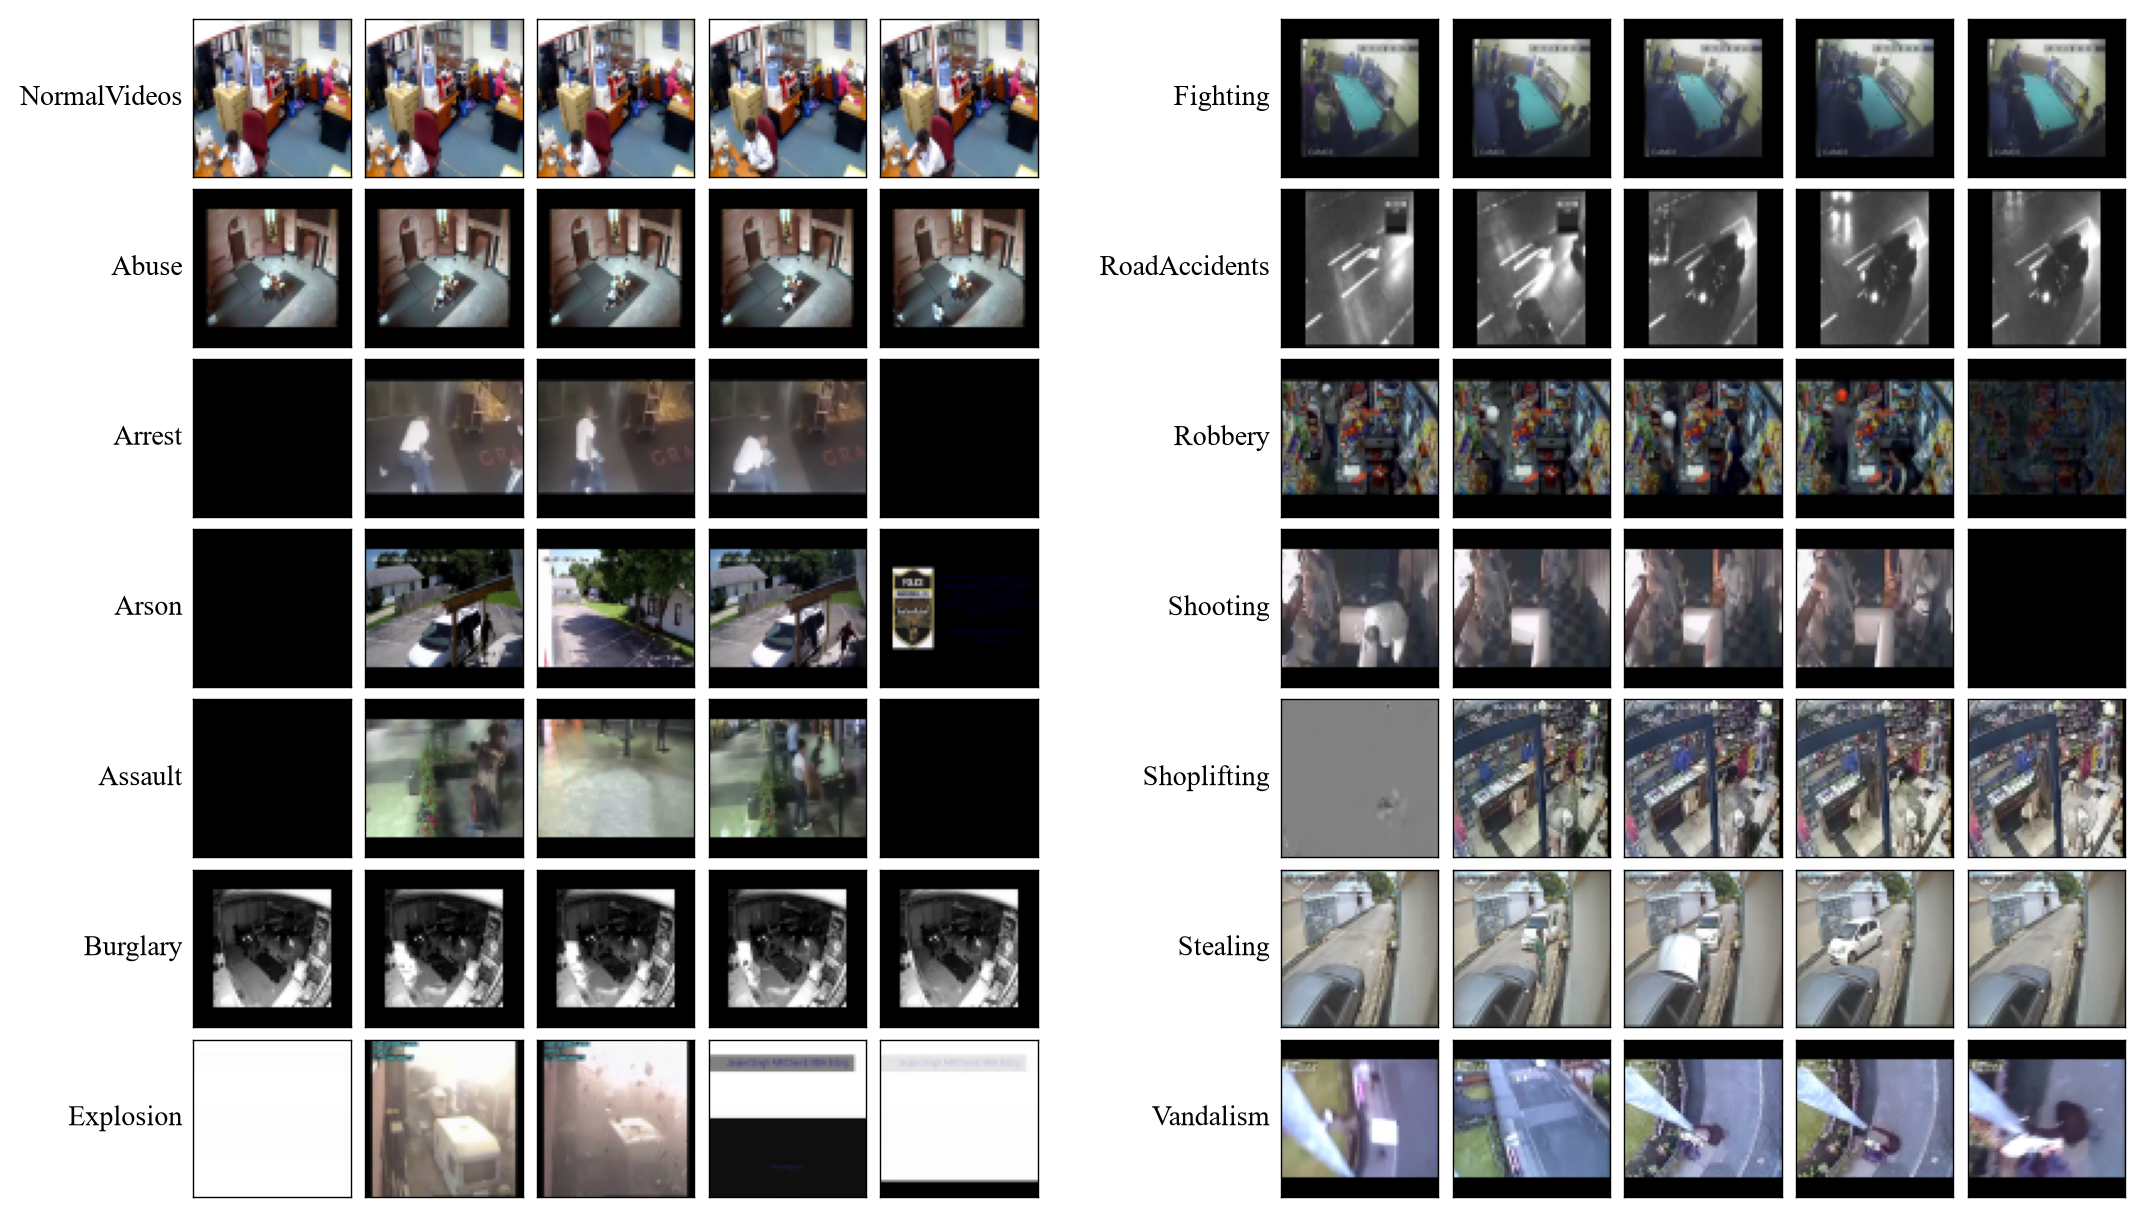

,videos,frames,black_pct,blank_pct,bordered_videos_pct
label,,,,,
NormalVideos,950,1012720,0.26,0.08,66.32
Abuse,50,19373,0.58,0.15,68.00
Arrest,50,29762,0.44,0.09,68.00
Arson,50,27214,1.00,0.19,66.00
Assault,50,13017,0.61,0.16,60.00
Burglary,100,47161,0.42,0.18,60.00
Explosion,50,25263,0.74,0.13,66.00
Fighting,50,25915,0.63,0.19,54.00
RoadAccidents,150,26149,0.41,0.12,55.33


In [7]:
display(Image(eda.FIG_DIR / 'sample_frames.png'))
noise = eda.TAB_DIR / 'noise.csv'
display(pd.read_csv(noise, index_col=0) if noise.exists() else Markdown('*noise scan not run yet*'))

## Preprocessing pipeline

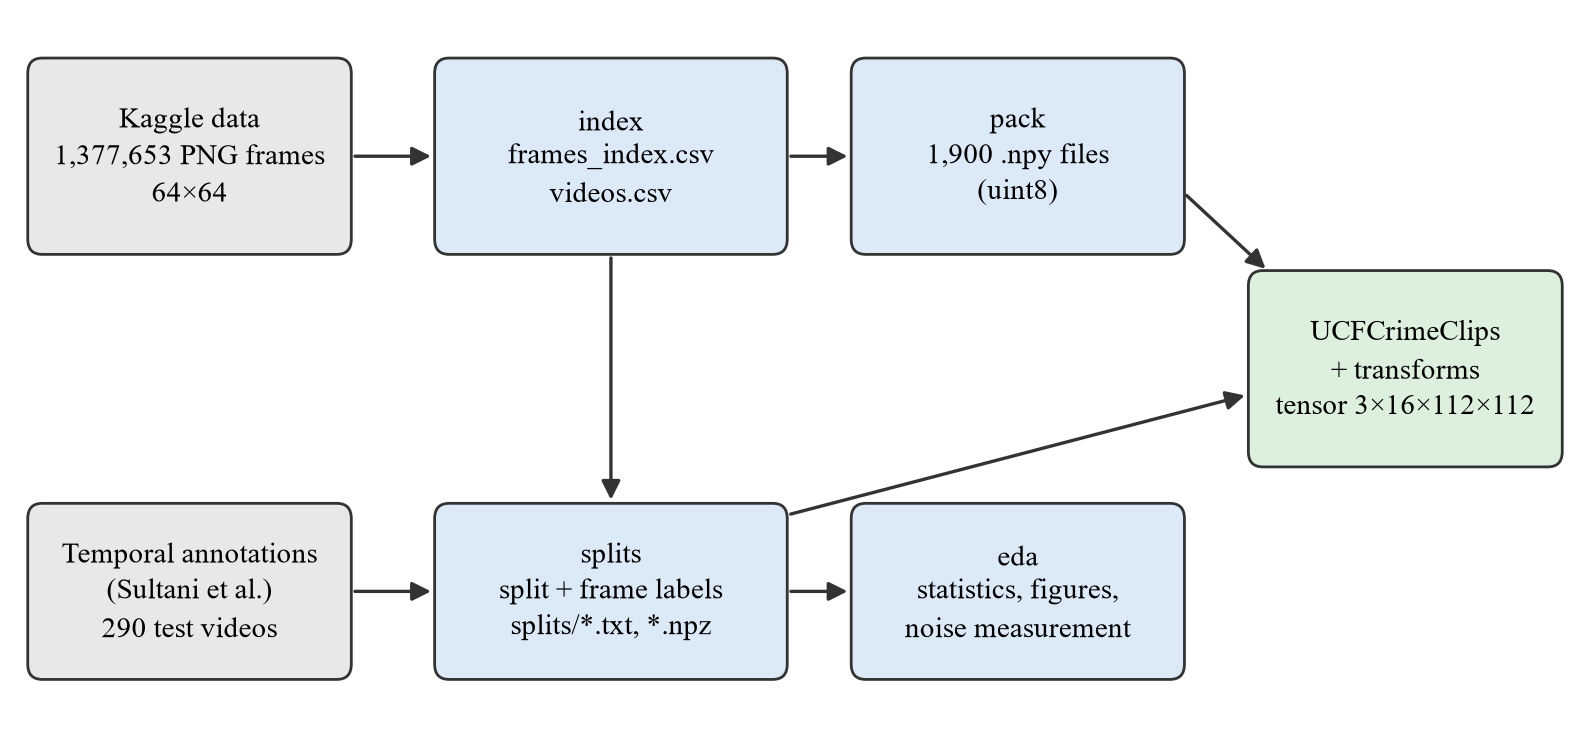

In [8]:
display(Image(eda.FIG_DIR / 'pipeline.png'))